In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
df = pd.read_csv("/content/cloud_dataset.csv")

df.head()


,Timestamp,CPU_Usage,Memory_Usage,Disk_IO,Network_IO,Workload_Type,User_ID,Anomaly_Label
0,2025-07-01 00:00:00,18.88,43.19,11.40,6.01,Database_Query,user_1,0
1,2025-07-01 00:01:00,25.31,45.43,7.68,17.67,Video_Streaming,user_1,0
2,2025-07-01 00:02:00,3.87,49.50,14.08,3.48,Database_Query,user_1,0
3,2025-07-01 00:03:00,20.92,25.88,17.33,4.77,Web_Service,user_1,0
4,2025-07-01 00:04:00,55.59,43.94,10.61,4.48,Web_Service,user_1,0


In [3]:
print("Shape of dataset:", df.shape)
print("\nData Types:\n")
print(df.info())
print("\nStatistical Summary:\n")
print(df.describe())


Shape of dataset: (14400, 8)

Data Types:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14400 entries, 0 to 14399
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Timestamp      14400 non-null  object 
 1   CPU_Usage      14400 non-null  float64
 2   Memory_Usage   14400 non-null  float64
 3   Disk_IO        14400 non-null  float64
 4   Network_IO     14400 non-null  float64
 5   Workload_Type  14400 non-null  object 
 6   User_ID        14400 non-null  object 
 7   Anomaly_Label  14400 non-null  int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 900.1+ KB
None

Statistical Summary:

          CPU_Usage  Memory_Usage       Disk_IO    Network_IO  Anomaly_Label
count  14400.000000  14400.000000  14400.000000  14400.000000   14400.000000
mean      35.558222     44.153315     12.598681      7.993522       0.087292
std       19.218739     15.300254      9.550537      6.460288       0.282272
min      

In [4]:
print("\nMissing Values:\n")
print(df.isnull().sum())
df.fillna(df.median(numeric_only=True), inplace=True)



Missing Values:

Timestamp        0
CPU_Usage        0
Memory_Usage     0
Disk_IO          0
Network_IO       0
Workload_Type    0
User_ID          0
Anomaly_Label    0
dtype: int64


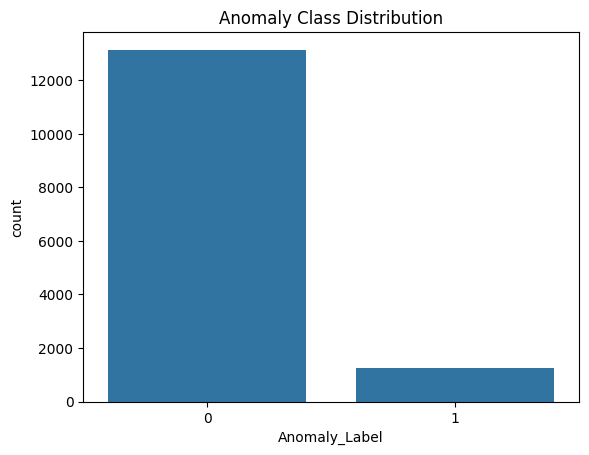

Anomaly_Label
0    13143
1     1257
Name: count, dtype: int64


In [5]:
sns.countplot(x='Anomaly_Label', data=df)
plt.title("Anomaly Class Distribution")
plt.show()

print(df['Anomaly_Label'].value_counts())


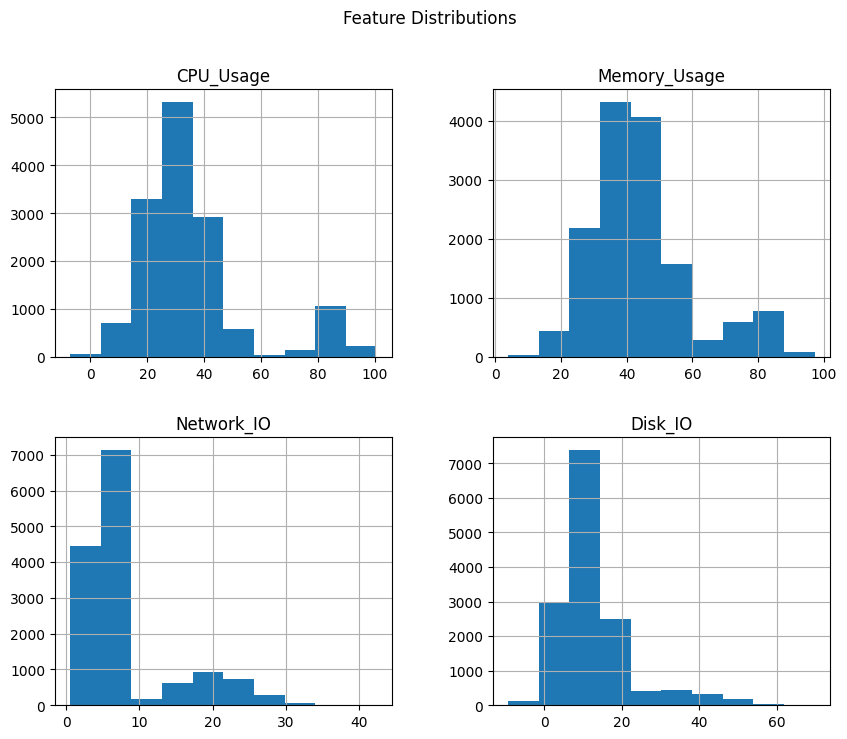

In [6]:
features = ['CPU_Usage', 'Memory_Usage', 'Network_IO', 'Disk_IO']

df[features].hist(figsize=(10,8))
plt.suptitle("Feature Distributions")
plt.show()


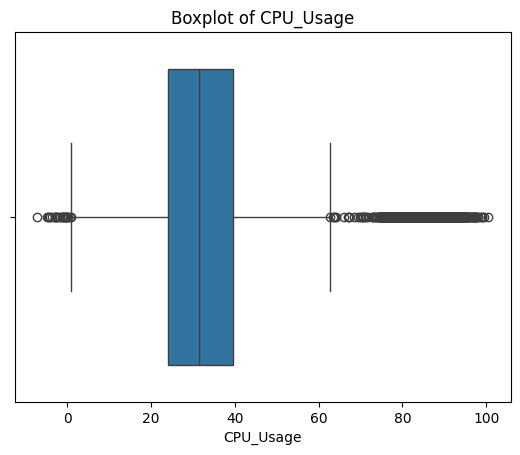

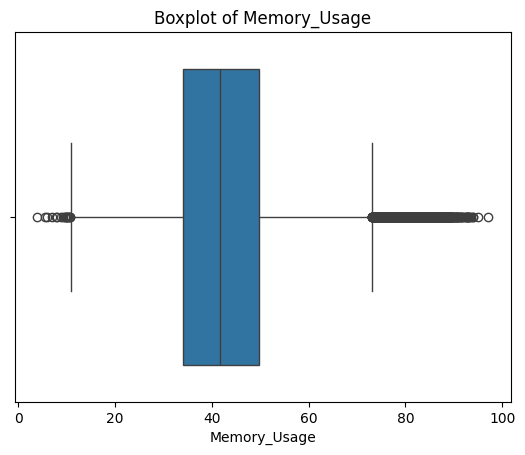

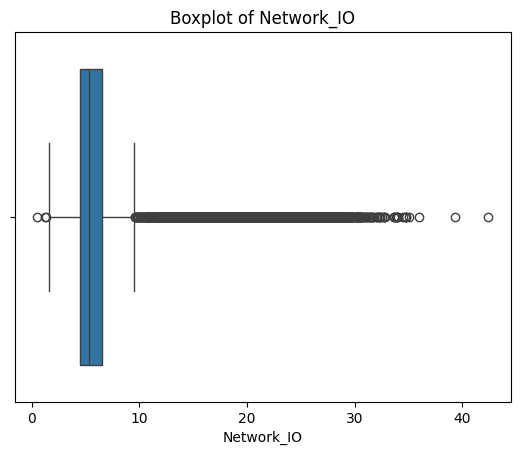

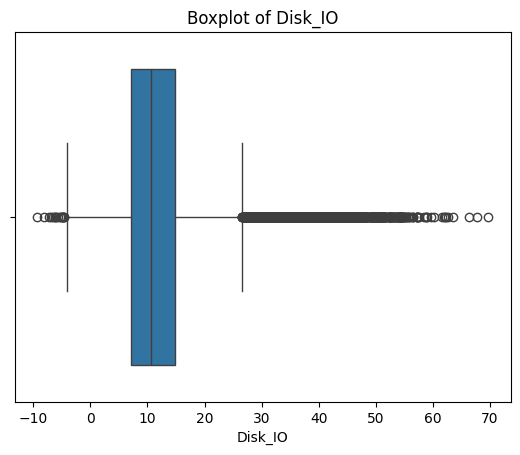

In [20]:
for col in features:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


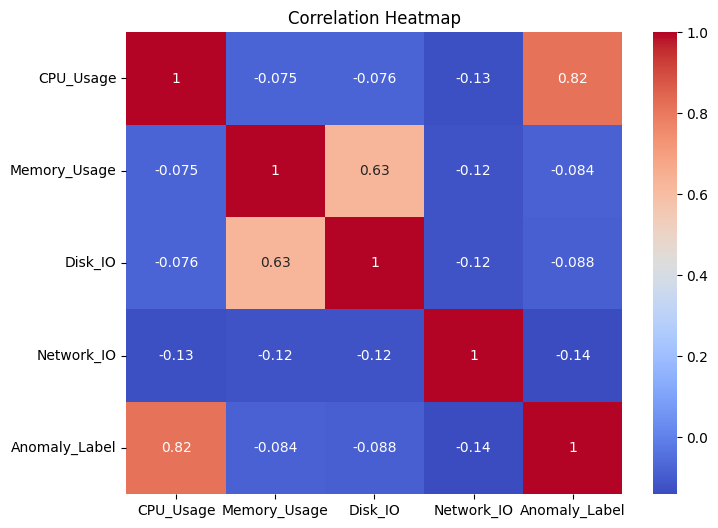

In [8]:
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [9]:
X = df[features]
y = df['Anomaly_Label']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [11]:
clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

clf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=42)

In [12]:
y_pred = clf.predict(X_test)


In [13]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Accuracy: 1.0

Confusion Matrix:

[[2629    0]
 [   0  251]]

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2629
           1       1.00      1.00      1.00       251

    accuracy                           1.00      2880
   macro avg       1.00      1.00      1.00      2880
weighted avg       1.00      1.00      1.00      2880



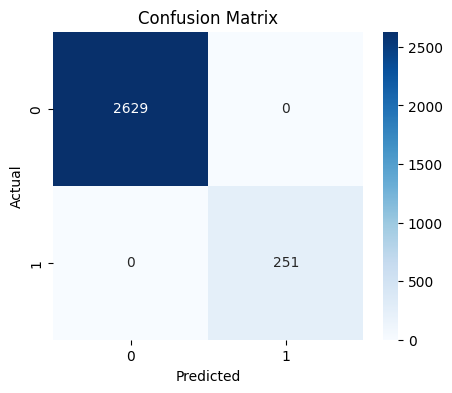

In [14]:
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


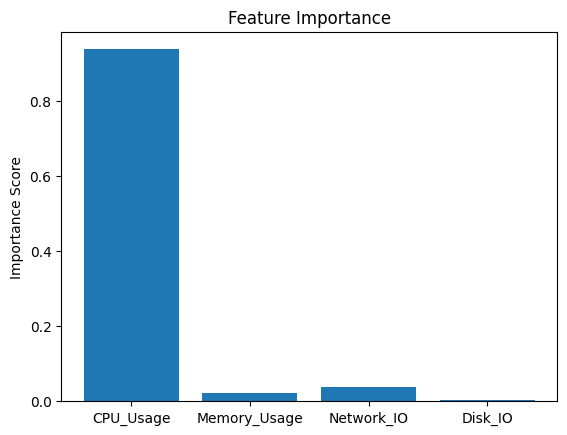

In [15]:
importance = clf.feature_importances_

plt.figure()
plt.bar(features, importance)
plt.title("Feature Importance")
plt.ylabel("Importance Score")
plt.show()


In [ ]:
# Ask user to enter values
cpu = float(input("Enter CPU Usage (0 to 100): "))
memory = float(input("Enter Memory Usage (0 to 100): "))
network = float(input("Enter Network IO (0 to 100): "))
disk = float(input("Enter Disk IO (0 to 100): "))

# Create DataFrame from user input
new_service = pd.DataFrame({
    'CPU_Usage': [cpu],
    'Memory_Usage': [memory],
    'Network_IO': [network],
    'Disk_IO': [disk]
})

# Make prediction
prediction = clf.predict(new_service)

# Display result
if prediction[0] == 1:
    print("Anomalous Service ")
else:
    print("Normal Service ")
